<a href="https://colab.research.google.com/github/senchiao/HRRR_plots/blob/main/JMA_MSM_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%matplotlib inline
!pip install pygrib
!pip install cartopy
!pip install basemap
import pygrib
import matplotlib.pyplot as plt
from datetime import datetime
import urllib
import numpy as np
from mpl_toolkits.basemap import Basemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.5/30.5 MB 40.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 60.8 MB/s  0:00:00
  Attempting uninstall: pyshp
    Found existing installation: pyshp 3.1.6
    Uninstalling pyshp-3.1.6:
      Successfully uninstalled pyshp-3.1.6
  Attempting uninstall: pyproj
    Found existing installation: pyproj 3.8.0
    Uninstalling pyproj-3.8.0:
      Successfully uninstalled pyproj-3.8.0
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successfully uninstalled packaging-26.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [basemap]


In [4]:
filename = '/content/Z__C_RJTD_20251110000000_MSM_GPV_Rjp_L-pall_FH00-15_grib2.bin'
grbs = pygrib.open(filename)

In [22]:
# Print an inventory of the file
grbs.seek(0) #(go back to top of file)
for grb in grbs:
    grb
    #grb  ## Yeah, we really don't need to look at all the lines.

In [33]:
variables = ['Temperature','Relative humidity','Vertical Velocity']
figure_num = 1
for v in variables:
    # find first grb message with a matching name
    grb = grbs.select(name='V component of wind')[0]  # the number in brackets is the level [0] surface, [-1] model top
    # Print grb - there is some good info in here, like the model level
    print(grb)
    grb

63:V component of wind:m s**-1 (instant):regular_ll:isobaricInhPa:level 40000.0 Pa:fcst time 0 hrs:from 202511100000
63:V component of wind:m s**-1 (instant):regular_ll:isobaricInhPa:level 40000.0 Pa:fcst time 0 hrs:from 202511100000
63:V component of wind:m s**-1 (instant):regular_ll:isobaricInhPa:level 40000.0 Pa:fcst time 0 hrs:from 202511100000


In [16]:
G = grbs[55]
G
G.name

'Geopotential height'

In [53]:
z500_msg = grbs.select(name='Geopotential height', level=500)[0]
z500 = z500_msg.values
#print(z500_msg.name)
#print(z500)

Geopotential height


In [17]:
G.analDate
G.validDate
G.fcstimeunits
G.projparams

{'a': 6371229, 'b': 6371229, 'proj': 'longlat'}

In [18]:
data, lats, lons = G.data()

Text(0.5, 1.0, 'Valid Date: 2025-Nov-10 00:00:00\nVariable: Geopotential height\n Level: 500')

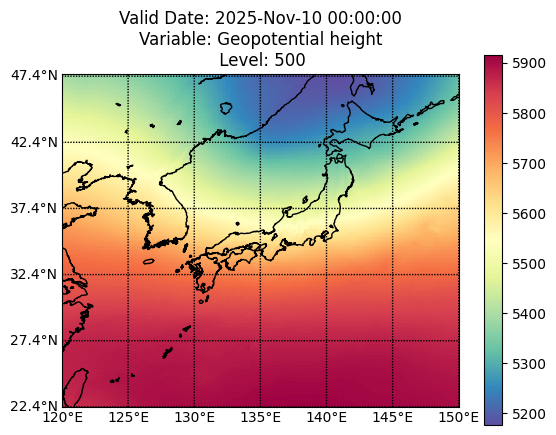

In [52]:
bot_left_lon  = lons.min()
bot_left_lat  = lats.min()
top_right_lon = lons.max()
top_right_lat = lats.max()
m = Basemap(resolution='i',projection='cyl',\
                llcrnrlon=bot_left_lon,llcrnrlat=bot_left_lat,\
                urcrnrlon=top_right_lon,urcrnrlat=top_right_lat,)
m.drawstates()
m.drawcoastlines()

# Draw latitude lines (parallels) and longitude lines (meridians) with labels
m.drawparallels(np.arange(bot_left_lat, top_right_lat+1, 5), labels=[1,0,0,0], fontsize=10)
m.drawmeridians(np.arange(bot_left_lon, top_right_lon+1, 5), labels=[0,0,0,1], fontsize=10)

plt.pcolormesh(lons, lats, data, cmap='Spectral_r')
plt.colorbar()
#plt.title('%s (%s)' % (G.name, G.units))
plt.title('Valid Date: '+validDate.strftime('%Y-%b-%d %H:%M:%S')+'\n'+
              'Variable: '+z500_msg.name+"\n Level: "+str(z500_msg.level))

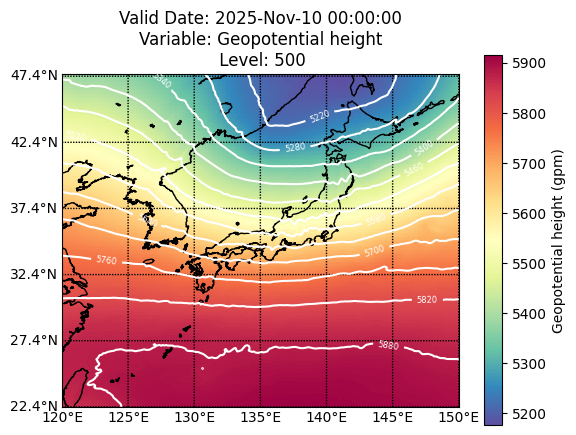

In [51]:
m.drawstates()
m.drawcoastlines()
m.pcolormesh(lons, lats, z500, cmap='Spectral_r')

# Draw latitude lines (parallels) and longitude lines (meridians) with labels
m.drawparallels(np.arange(bot_left_lat, top_right_lat+1, 5), labels=[1,0,0,0], fontsize=10)
m.drawmeridians(np.arange(bot_left_lon, top_right_lon+1, 5), labels=[0,0,0,1], fontsize=10)

cb = plt.colorbar()
cb.set_label(z500_msg.name + " (" + z500_msg.units + ")")

# Just becuase we can, add 500 mb Geopotential Height Contours on top.
CS = m.contour(lons,lats,z500,colors='white',levels=np.arange(0,6000,60))
plt.clabel(CS, inline=1, fontsize=6,fmt='%1.0f')

validDate = grb.validDate
plt.title('Valid Date: '+validDate.strftime('%Y-%b-%d %H:%M:%S')+'\n'+
              'Variable: '+z500_msg.name+"\n Level: "+str(z500_msg.level))
figure_num += 1